# v2w · v2 rebuilt with weekly decisions

Plan: [docs/weekly_rebuild_note.md](../docs/weekly_rebuild_note.md), fixed and hashed before this notebook existed. Everything in [docs/v2_design_note.md](../docs/v2_design_note.md) is kept, **except that every backtest decides once a week**: after the week's last close, the expected-return rule turns that day's prediction into Buy, Hold or Sell for the next 5 trading days, the trade fills at the next open, and the position is held all week. Models still learn from every trading day. Outputs go to `outputs/weekly/v2/`.

| Step | Data used | Decides |
|---|---|---|
| Hyper-parameter search (C5) | **Train 2010–2020**, `TimeSeriesSplit(5, gap=6)`, scored by **log loss** | parameters of LR, RF, HGB |
| Joint selection (C6) | **Validation 2021–2022** backtest, models trained on Train only | model × default (long / cash), by after-cost Sharpe over T-bills; ties → fewer trades |
| Freeze | — | `outputs/v2/frozen_config.json` |
| **Test (once)** | **2023–2024**, refit on Train + Val | nothing |
| Evidence | test period; walk-forward 2013–2024 | nothing (reporting only) |

**Label (C1):** Open(t+1) → Open(t+6), classed at ±1%. It reads 6 bars ahead, so every split uses `gap = config.V2_GAP = 6`.
**Rule (C2–C4):** E[r] = Σ P(class)·μ(class), with μ from the training rows of the same fit. Default-long exits when E[r] < −0.30% and re-enters when E[r] ≥ 0. Default-cash enters when E[r] > +0.30% and exits when E[r] ≤ 0.
**Cash (C7):** earns the 13-week T-bill rate (lagged one day). Sharpe is measured over that rate.

*Disclosure: this rebuild was decided after all daily results, including 2023–24, were known. The test is a seen-period result (see the plan).*

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone

from src import config, v2, weekly
from src.data import load_snapshot
from src.dataset import build_dataset_v2
from src.features import FEATURE_COLS
from src.split import get_segments, make_cv, train_val_combined
from src.models import baselines, tune
from src.evaluate import classification_metrics

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
np.random.seed(config.SEED)
OUT = config.OUTPUT_DIR / "weekly" / "v2"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Data, label, segments (gap 6) and the T-bill rate

In [2]:
raw = load_snapshot()
prices = raw[["Open", "Close"]]
ds = build_dataset_v2(raw)
segs = get_segments(ds, gap=config.V2_GAP)          # test is NOT loaded here
train, val = segs["train"], segs["val"]
Xtr, ytr = train[FEATURE_COLS], train["label"].astype(int)
Xva, yva = val[FEATURE_COLS], val["label"].astype(int)
val_days = ds.loc[config.VAL[0]:config.VAL[1]]      # every validation day, for the backtest
cv = make_cv(gap=config.V2_GAP)

if not list(config.RAW_DIR.glob("irx_*.csv")):
    print("downloaded", v2.download_tbill_snapshot().name)
rf = v2.load_tbill_daily(raw.index)
print(f"train {len(train)} rows {train.index.min().date()}→{train.index.max().date()} | "
      f"val {len(val)} rows {val.index.min().date()}→{val.index.max().date()}")
print("class share (train):", ytr.map(config.CLASS_NAMES).value_counts(normalize=True).round(3).to_dict())
print(f"T-bill rate, annualised: 2021–22 mean {rf.loc['2021':'2022'].mean()*252:.2%}, "
      f"2023–24 mean {rf.loc['2023':'2024'].mean()*252:.2%}")

train 2763 rows 2010-01-04→2020-12-22 | val 497 rows 2021-01-04→2022-12-21
class share (train): {'Hold': 0.448, 'Buy': 0.35, 'Sell': 0.202}
T-bill rate, annualised: 2021–22 mean 1.00%, 2023–24 mean 5.00%


## 2. Hyper-parameter search on log loss (C5)

In [3]:
SEARCH = {name: tune(name, Xtr, ytr, cv, n_iter=20, scoring="neg_log_loss")
          for name in ["LR", "RF", "HGB"]}
rows = []
for name, s in SEARCH.items():
    i = s.best_index_
    p = s.best_estimator_.predict_proba(Xva)
    m = classification_metrics(yva, s.best_estimator_.classes_[p.argmax(1)], p)
    rows.append({"model": name, "cv_log_loss": -s.cv_results_["mean_test_score"][i],
                 "cv_std": s.cv_results_["std_test_score"][i], "val_log_loss": m["log_loss"],
                 "val_macro_f1": m["macro_f1"], "params": {k.replace("clf__", ""): v for k, v in s.best_params_.items()}})
tuning = pd.DataFrame(rows).set_index("model")
print("uniform guess log loss = ln 3 =", round(np.log(3), 4))
tuning

uniform guess log loss = ln 3 = 1.0986


,cv_log_loss,cv_std,val_log_loss,val_macro_f1,params
model,,,,,
LR,1.0450,0.0580,1.1062,0.3662,{'C': 0.014618962793704957}
RF,1.0408,0.0228,1.0763,0.4272,"{'max_depth': 4, 'max_features': 0.5, 'min_sam..."
HGB,1.0452,0.0225,1.1144,0.3561,"{'l2_regularization': 0.17336465350777208, 'le..."


## 3. Joint selection on the validation backtest (C6)

In [4]:
mu_tr = v2.class_means(ytr, train["r_fwd"])
print("class means μ (train, 5-day open→open):", {config.CLASS_NAMES[k]: f"{v:+.4%}" for k, v in mu_tr.items()})
pv = prices.loc[val_days.index]
rf_v = rf.loc[val_days.index]

def run(proba_frame, mu, default, days, rf_seg):
    er = v2.expected_return(proba_frame, mu)
    pos = weekly.weekly_positions_from_er(er, default)
    held = v2.held_from_positions(pos, start=1 if default == "long" else 0)
    sim = v2.simulate(held, prices.loc[days], rf_seg)
    return er, held, sim

sel, VAL_RUNS = [], {}
for name, s in SEARCH.items():
    proba = pd.DataFrame(s.best_estimator_.predict_proba(val_days[FEATURE_COLS]),
                         index=val_days.index, columns=s.best_estimator_.classes_)
    for default in v2.DEFAULTS:
        er, held, sim = run(proba, mu_tr, default, val_days.index, rf_v)
        VAL_RUNS[(name, default)] = (er, held, sim)
        sel.append({"model": name, "default": default, **v2.summarize(sim, held, rf_v, f"{name}·{default}")})
bh_held = v2.buy_and_hold_held(val_days.index)
bh_val = v2.summarize(v2.simulate(bh_held, pv, rf_v), bh_held, rf_v, "Buy & Hold")
selection = pd.DataFrame(sel).drop(columns="strategy").sort_values(["sharpe_excess", "round_trips"], ascending=[False, True])
display(selection)
print("Validation Buy & Hold:", {k: bh_val[k] for k in ["final_value", "sharpe_excess", "max_drawdown"]})
pick = selection.iloc[0]
PICK = {"model": pick["model"], "default": pick["default"]}
print("Selected:", PICK, "| beats Buy & Hold's validation Sharpe:", bool(pick["sharpe_excess"] > bh_val["sharpe_excess"]))

class means μ (train, 5-day open→open): {'Sell': '-2.7963%', 'Hold': '+0.1319%', 'Buy': '+2.2379%'}


,model,default,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
1,LR,cash,105397.3200,0.0540,0.0267,0.1054,0.2070,-0.1668,2,0.1930,411.4400
2,RF,long,97864.3000,-0.0214,-0.0108,0.1297,-0.0960,-0.1167,8,0.3080,1579.0400
4,HGB,long,92451.1400,-0.0755,-0.0386,0.1539,-0.2440,-0.1835,7,0.3980,1285.0100
0,LR,long,86945.8400,-0.1305,-0.0677,0.1670,-0.3970,-0.2209,3,0.4510,479.5200
5,HGB,cash,91932.0500,-0.0807,-0.0413,0.1002,-0.4720,-0.1779,5,0.1350,940.8100
3,RF,cash,102025.7600,0.0203,0.0101,0.0009,-0.7090,0.0000,0,0.0000,0.0000


Validation Buy & Hold: {'final_value': 104773.32, 'sharpe_excess': 0.166, 'max_drawdown': -0.245}
Selected: {'model': 'LR', 'default': 'cash'} | beats Buy & Hold's validation Sharpe: True


## 4. Freeze the configuration

In [5]:
best = SEARCH[PICK["model"]]
FROZEN = {
    "model": PICK["model"], "default": PICK["default"],
    "params": {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in best.best_params_.items()},
    "label": "±1% open(t+1)→open(t+6)", "gap": config.V2_GAP, "hurdle": v2.ROUND_TRIP,
    "mu_note": "class means re-estimated on the training rows of every fit",
    "val_sharpe_excess": float(pick["sharpe_excess"]), "val_final_value": float(pick["final_value"]),
    "val_bh_sharpe_excess": bh_val["sharpe_excess"], "schedule": "weekly", "frozen_before_test": True,
    "plan_sha256": (config.ROOT / "docs" / "weekly_rebuild_note.sha256").read_text().split()[0],
}
(OUT / "frozen_config.json").write_text(json.dumps(FROZEN, indent=2, default=str))
FROZEN

{'model': 'LR',
 'default': 'cash',
 'params': {'clf__C': 0.014618962793704957},
 'label': '±1% open(t+1)→open(t+6)',
 'gap': 6,
 'hurdle': 0.003,
 'mu_note': 'class means re-estimated on the training rows of every fit',
 'val_sharpe_excess': 0.207,
 'val_final_value': 105397.32,
 'val_bh_sharpe_excess': 0.166,
 'schedule': 'weekly',
 'frozen_before_test': True,
 'plan_sha256': '82602bdd44c1797b167933a11fe610c823d14ef2133ef9eed99a742a59ae644a'}

## 5. The test, opened once (2023–2024)
Refit on Train + Val (last 6 rows dropped), with μ re-estimated on the same rows. Nothing below changes any choice above.

In [6]:
tv = train_val_combined(ds, gap=config.V2_GAP)
final = clone(best.best_estimator_).fit(tv[FEATURE_COLS], tv["label"].astype(int))
mu_tv = v2.class_means(tv["label"], tv["r_fwd"])
test = get_segments(ds, gap=config.V2_GAP, include_test=True)["test"]   # <- the ONLY place test labels are read
test_days = ds.loc[config.TEST[0]:config.TEST[1]]
proba_te = pd.DataFrame(final.predict_proba(test_days[FEATURE_COLS]), index=test_days.index, columns=final.classes_)
rf_t = rf.loc[test_days.index]
er_te, held_te, sim_te = run(proba_te, mu_tv, FROZEN["default"], test_days.index, rf_t)
bh_held_te = v2.buy_and_hold_held(test_days.index)
bh_sim_te = v2.simulate(bh_held_te, prices.loc[test_days.index], rf_t)
res_te = pd.DataFrame([v2.summarize(sim_te, held_te, rf_t, f"v2 · {FROZEN['model']} · default-{FROZEN['default']}"),
                       v2.summarize(bh_sim_te, bh_held_te, rf_t, "Buy & Hold SPY")]).set_index("strategy")
v1_bt = json.loads((config.OUTPUT_DIR / "backtest_metrics.json").read_text())
v1_final = next(r["final_value"] for r in v1_bt["test"] if r["strategy"].startswith("Model · frozen rule (long-only)"))
display(res_te)
print(f"v1 primary (reference, same period): ${v1_final:,.0f}")

# classification on the labelled test rows
yte = test["label"].astype(int)
p_lab = proba_te.loc[test.index]
pred_te = p_lab.columns[p_lab.to_numpy().argmax(1)]
cls = {"v2 model": classification_metrics(yte, pred_te, p_lab.to_numpy())}
B = baselines()
for bname in ["B0_majority", "B1_stratified"]:
    est = B[bname].fit(tv[FEATURE_COLS], tv["label"].astype(int))
    cls[bname] = classification_metrics(yte, est.predict(test[FEATURE_COLS]))
cls_te = pd.DataFrame(cls).T[["n", "accuracy", "macro_f1", "recall_Sell", "recall_Hold", "recall_Buy", "log_loss"]]
cls_te

,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v2 · LR · default-cash,110452.6600,0.1045,0.0512,0.0003,-0.7090,0.0000,0,0.0000,0.0000
Buy & Hold SPY,156546.2500,0.5655,0.2523,0.1283,1.4300,-0.0997,1,1.0000,99.9000


v1 primary (reference, same period): $123,714


,n,accuracy,macro_f1,recall_Sell,recall_Hold,recall_Buy,log_loss
v2 model,496.0000,0.4536,0.4043,0.3021,0.7376,0.2374,1.0506
B0_majority,496.0000,0.4073,0.1929,0.0000,1.0000,0.0000,NaN
B1_stratified,496.0000,0.3387,0.3173,0.2396,0.4356,0.2879,NaN


## 6. Evidence on the test period

{
 "random_timing_percentile": 0.0,
 "random_median_final": 110452.66,
 "sharpe_diff_vs_bh_ci95": [
  -5.044,
  -1.064
 ],
 "macro_f1_diff_vs_B1_ci95": [
  0.012,
  0.152
 ],
 "n_cash_spells": 0
}


""


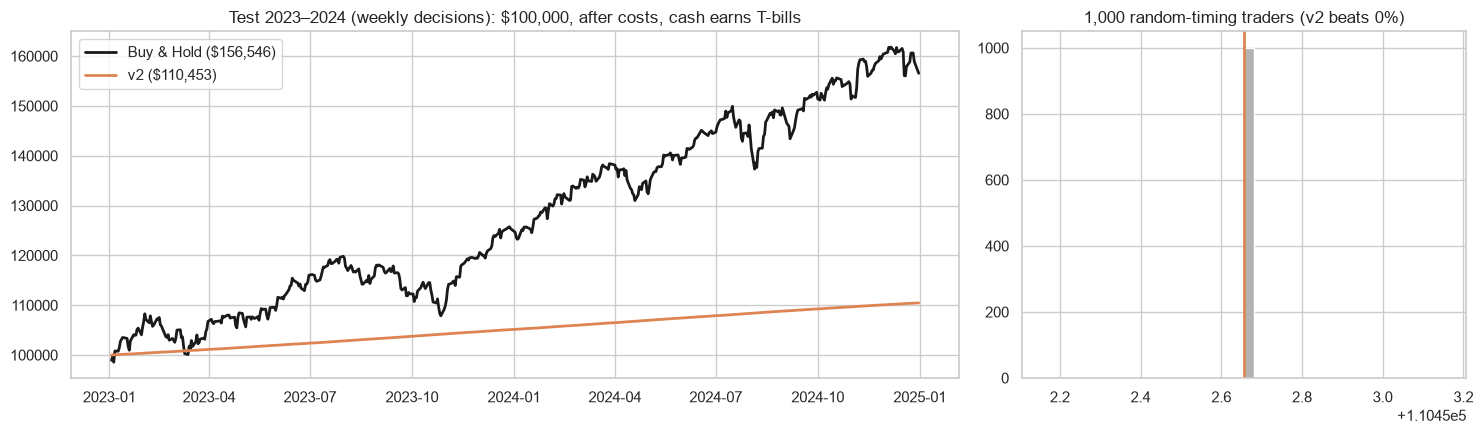

In [7]:
pt = prices.loc[test_days.index]
rand = v2.random_timing_benchmark(held_te, pt, rf_t, n=1000)
pct = float((rand < sim_te["value"].iloc[-1]).mean())
r_s = sim_te["value"].pct_change().fillna(sim_te["value"].iloc[0] / config.INIT_CASH - 1)
r_b = bh_sim_te["value"].pct_change().fillna(bh_sim_te["value"].iloc[0] / config.INIT_CASH - 1)
sh_ci = np.percentile(v2.bootstrap_sharpe_diff(r_s, r_b, rf_t), [2.5, 50, 97.5])
b1 = B["B1_stratified"].predict(test[FEATURE_COLS])
f1_ci = np.percentile(v2.bootstrap_f1_diff(yte, pred_te, b1), [2.5, 50, 97.5])
attr = v2.out_of_market_attribution(held_te, pt)
EVID = {"random_timing_percentile": round(pct, 3), "random_median_final": round(float(rand.median()), 2),
        "sharpe_diff_vs_bh_ci95": [round(float(x), 3) for x in sh_ci[[0, 2]]],
        "macro_f1_diff_vs_B1_ci95": [round(float(x), 3) for x in f1_ci[[0, 2]]],
        "n_cash_spells": int(len(attr))}
print(json.dumps(EVID, indent=1))
display(attr)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(bh_sim_te["value"], color="k", lw=2, label=f"Buy & Hold (${bh_sim_te['value'].iloc[-1]:,.0f})")
ax[0].plot(sim_te["value"], color="C1", lw=2, label=f"v2 (${sim_te['value'].iloc[-1]:,.0f})")
ax[0].set_title("Test 2023–2024 (weekly decisions): $100,000, after costs, cash earns T-bills"); ax[0].legend()
ax[1].hist(rand, bins=40, color="0.7"); ax[1].axvline(sim_te["value"].iloc[-1], color="C1", lw=2)
ax[1].set_title(f"1,000 random-timing traders (v2 beats {pct:.0%})")
plt.tight_layout(); savefig("test_equity_and_random"); plt.show()

## 7. Walk-forward 2013–2024 (reporting only)
The frozen configuration is refit every January on all earlier rows whose labels are known (last 6 rows dropped), with μ re-estimated each time. The rule runs continuously across years.

,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v2 walk-forward,140013.2400,0.4001,0.0285,0.0301,0.4600,-0.0469,8,0.0190,1833.2000
Buy & Hold,499270.9200,3.9927,0.1436,0.1670,0.8000,-0.3372,1,1.0000,99.9000


,v2,Buy & Hold,v2 − B&H,exposure
Date,,,,
2013,0.0005,0.2900,-0.2895,0.0000
2014,0.0158,0.1456,-0.1298,0.0397
2015,0.0051,0.0129,-0.0077,0.0357
2016,0.0406,0.1359,-0.0953,0.0198
2017,0.0092,0.2078,-0.1986,0.0000
2018,0.1178,-0.0525,0.1702,0.0398
2019,0.0290,0.3109,-0.2819,0.0119
2020,0.0076,0.1724,-0.1647,0.0593
2021,0.0003,0.3051,-0.3047,0.0000


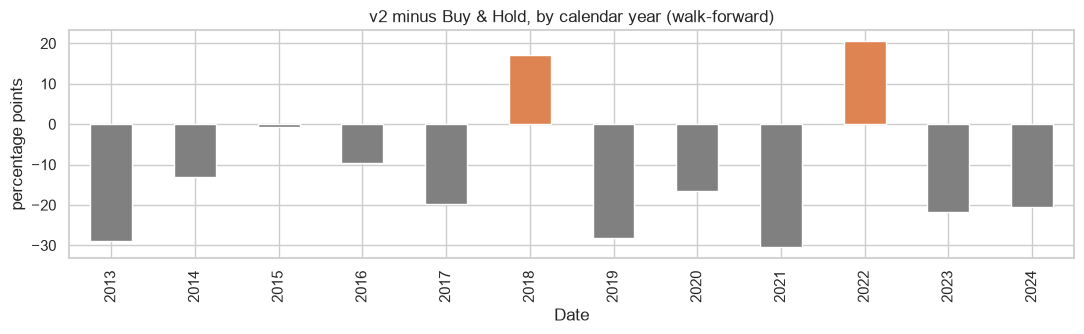

In [8]:
def wf_proba(year):
    start = pd.Timestamp(f"{year}-01-01")
    hist = ds.loc["2006-01-01":start - pd.Timedelta(days=1)].dropna(subset=["label"]).iloc[:-config.V2_GAP]
    m = clone(best.best_estimator_).fit(hist[FEATURE_COLS], hist["label"].astype(int))
    mu = v2.class_means(hist["label"], hist["r_fwd"])
    days = ds.loc[f"{year}-01-01":f"{year}-12-31"]
    p = pd.DataFrame(m.predict_proba(days[FEATURE_COLS]), index=days.index, columns=m.classes_)
    return v2.expected_return(p, mu)

er_wf = pd.concat([wf_proba(y) for y in range(2013, 2025)])
pos_wf = weekly.weekly_positions_from_er(er_wf, FROZEN["default"])
held_wf = v2.held_from_positions(pos_wf, start=1 if FROZEN["default"] == "long" else 0)
rf_w = rf.loc[er_wf.index]
sim_wf = v2.simulate(held_wf, prices.loc[er_wf.index], rf_w)
bh_wf = v2.simulate(v2.buy_and_hold_held(er_wf.index), prices.loc[er_wf.index], rf_w)
yr = pd.DataFrame({"v2": sim_wf["value"], "Buy & Hold": bh_wf["value"]})
yearly = yr.groupby(yr.index.year).apply(lambda g: g.iloc[-1] / g.iloc[0] - 1)
yearly["v2 − B&H"] = yearly["v2"] - yearly["Buy & Hold"]
yearly["exposure"] = held_wf.groupby(held_wf.index.year).mean()
wf_sum = pd.DataFrame([v2.summarize(sim_wf, held_wf, rf_w, "v2 walk-forward"),
                       v2.summarize(bh_wf, v2.buy_and_hold_held(er_wf.index), rf_w, "Buy & Hold")]).set_index("strategy")
display(wf_sum); display(yearly)
ax = (yearly["v2 − B&H"] * 100).plot(kind="bar", figsize=(11, 3.5), color=np.where(yearly["v2 − B&H"] >= 0, "C1", "0.5"))
ax.set_ylabel("percentage points"); ax.set_title("v2 minus Buy & Hold, by calendar year (walk-forward)")
plt.tight_layout(); savefig("walk_forward_yearly"); plt.show()

## 8. Save results

In [9]:
idx = test_days.index
paths = {"dates": [d.strftime("%Y-%m-%d") for d in idx], "v2": sim_te["value"].round(0).tolist(),
         "bh": bh_sim_te["value"].round(0).tolist()}
results = {"frozen_config": FROZEN, "tuning": tuning.drop(columns="params").round(4).to_dict(orient="index"),
           "validation_selection": selection.to_dict(orient="records"), "validation_bh": bh_val,
           "test": res_te.reset_index().to_dict(orient="records"), "test_classification": cls_te.to_dict(orient="index"),
           "v1_test_final_value": v1_final, "evidence": EVID, "attribution": attr.astype(str).to_dict(orient="records"),
           "walk_forward": wf_sum.reset_index().to_dict(orient="records"),
           "walk_forward_yearly": yearly.round(4).reset_index(names="year").to_dict(orient="records")}
def no_nan(o):  # strict JSON: NaN -> null
    if isinstance(o, dict): return {k: no_nan(v) for k, v in o.items()}
    if isinstance(o, list): return [no_nan(v) for v in o]
    return None if isinstance(o, float) and np.isnan(o) else o
(OUT / "results.json").write_text(json.dumps(no_nan(json.loads(json.dumps(results, default=str))), indent=2, allow_nan=False))
(OUT / "test_paths.json").write_text(json.dumps(paths))
pd.DataFrame({"E_r": er_te, "held": held_te, **{f"p_{config.CLASS_NAMES[c]}": proba_te[c] for c in proba_te}}).to_csv(OUT / "test_predictions.csv")
print("saved outputs/v2/results.json, test_paths.json, test_predictions.csv, figures/")

saved outputs/v2/results.json, test_paths.json, test_predictions.csv, figures/
